# Mini-Courier Planner
**Capstone Assignment – B.Tech**

This notebook demonstrates parcel prioritization, 0/1 knapsack, Dijkstra shortest paths, nearest-neighbor TSP approximation, and runtime benchmarking.

In [9]:
from pathlib import Path
import sys
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_loader import load_parcels, load_graph
from src.sorting import prioritize_parcels
from src.knapsack import knapsack_01
from src.graph import shortest_path, nearest_neighbor_tsp

In [10]:
parcels = load_parcels('datasets/parcels.csv')
graph = load_graph('datasets/routes.csv')
print('Parcels:', len(parcels))
print('Graph nodes:', len(graph))

Parcels: 12
Graph nodes: 6


## 1. Parcel Prioritization

In [11]:
ordered = prioritize_parcels(parcels)
for p in ordered:
    print(p['parcel_id'], p['destination'], p['deadline'], p['priority'])

P10 Faridabad 2026-10-07 Critical
P03 Noida 2026-10-07 Critical
P05 Ghaziabad 2026-10-08 High
P01 Delhi 2026-10-08 High
P09 Delhi 2026-10-08 High
P07 Gurgaon 2026-10-09 High
P04 Faridabad 2026-10-09 Medium
P11 Ghaziabad 2026-10-10 Medium
P02 Gurgaon 2026-10-10 Medium
P06 Delhi 2026-10-11 Low
P08 Noida 2026-10-12 Low
P12 Gurgaon 2026-10-13 Low


## 2. 0/1 Knapsack Packing

In [12]:
selected, total_weight, total_value, dp = knapsack_01(ordered, 25)
print('Selected:', [p['parcel_id'] for p in selected])
print('Weight:', total_weight, 'kg')
print('Value:', total_value)
print('DP dimensions:', len(dp), 'x', len(dp[0]))

Selected: ['P03', 'P01', 'P09']
Weight: 24 kg
Value: 170000.0
DP dimensions: 13 x 26


## 3. Dijkstra Shortest Path

In [13]:
path, dist = shortest_path(graph, 'Warehouse', 'Noida')
print(' -> '.join(path), dist, 'km')

Warehouse -> Noida 8.0 km


## 4. Nearest-Neighbor TSP Approximation

In [14]:
destinations = list(dict.fromkeys(p['destination'] for p in selected))
route, distance, _ = nearest_neighbor_tsp(graph, 'Warehouse', destinations)
print('Route:', ' -> '.join(route))
print('Distance:', distance, 'km')

Route: Warehouse -> Delhi -> Noida -> Warehouse
Distance: 24.0 km


## 5. Performance Benchmark

In [15]:
from src.benchmark import benchmark
import pandas as pd
results = pd.DataFrame(benchmark())
results

,input_size,sorting_ms,knapsack_ms,dijkstra_ms
0,10,0.046847,0.234178,0.033192
1,50,0.271905,1.097553,0.126533
2,100,0.683104,1.339936,0.255523
3,200,1.963858,1.655675,0.508467
4,500,5.135954,1.230780,1.660564


<Axes: title={'center': 'Runtime Comparison'}, xlabel='input_size'>

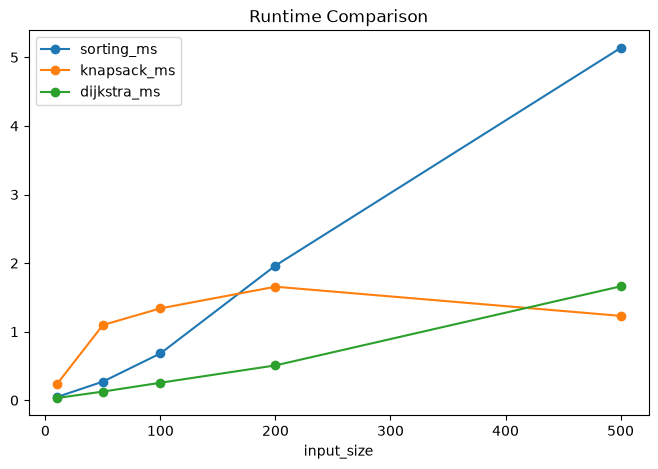

In [16]:
results.plot(x='input_size', y=['sorting_ms','knapsack_ms','dijkstra_ms'], marker='o', figsize=(8,5), title='Runtime Comparison')